# Set 8: EDA + Agglomerative Clustering

**Q1 → Exp 1A / 1B / 2** · **Q2 → Exp 6** (hierarchical clustering)

Datasets: Q1 `Diabetes.csv`, Q2 `IRIS.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 Display the outlier values of numerical columns using Z-score

In [3]:
num = df.select_dtypes("number")
z = ((num - num.mean()) / num.std()).abs()      # z-score: how many std-devs each value is from its column mean
for col in num.columns:
    outliers = num[col][z[col] > 3]
    print(f"{col}: {len(outliers)} outliers ->", outliers.values[:10])

Pregnancies: 4 outliers -> [15 17 14 14]
Glucose: 5 outliers -> [0 0 0 0 0]
BloodPressure: 35 outliers -> [0 0 0 0 0 0 0 0 0 0]
SkinThickness: 1 outliers -> [99]
Insulin: 18 outliers -> [543 846 495 485 495 478 744 680 545 465]
BMI: 14 outliers -> [ 0.   0.   0.   0.   0.  67.1  0.   0.  59.4  0. ]
DiabetesPedigreeFunction: 11 outliers -> [2.288 1.893 1.781 2.329 1.476 2.137 1.731 1.6   2.42  1.699]
Age: 5 outliers -> [69 72 81 70 69]
Outcome: 0 outliers -> []


### Q1.3 Univariate analysis of continuous variables (violin plot)

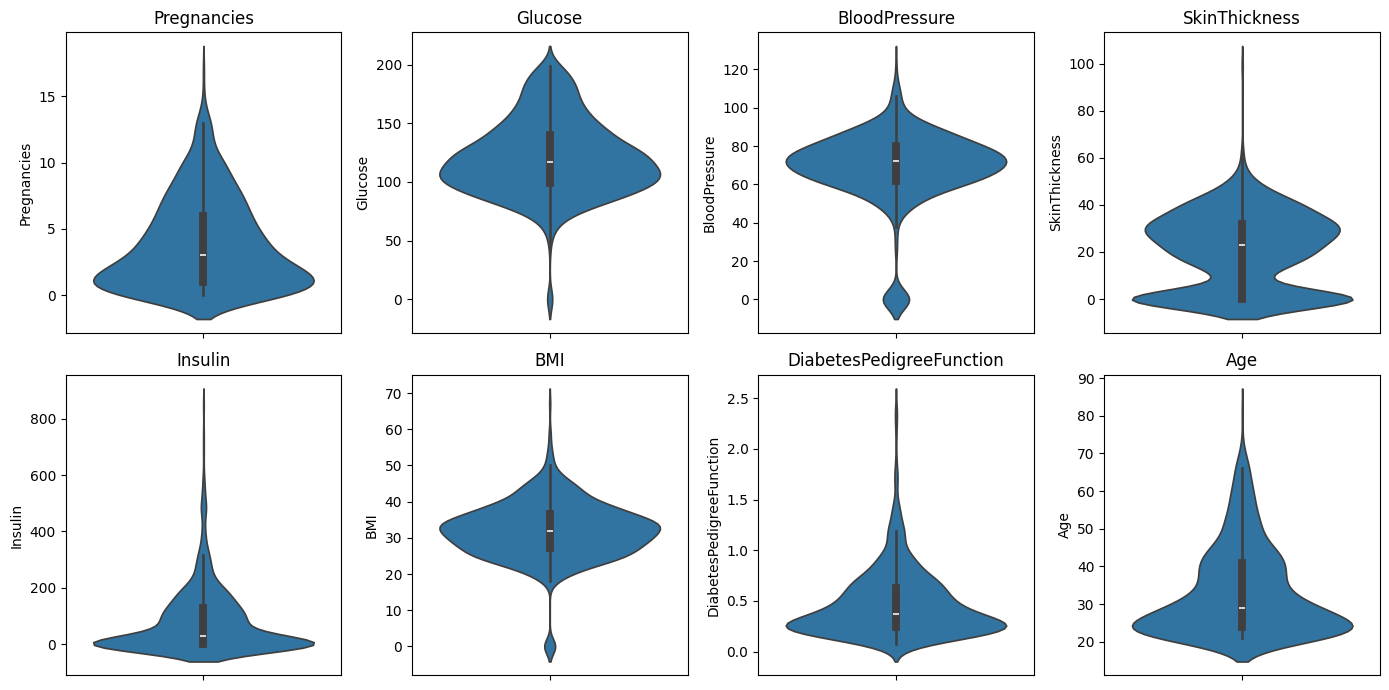

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.ravel(), df.columns[:8]):
    sns.violinplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Q1.4 Interpolation (nearest) for numerical columns with < 10% missing
First turn the impossible zeros into missing values, so there's something to fill.

In [5]:
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
pct = df.isnull().mean() * 100
for col in df.columns:
    if 0 < pct[col] < 10:
        df[col] = df[col].interpolate(method="nearest").bfill().ffill()   # copy the nearest known value
        print(f"{col}: {pct[col]:.1f}% missing -> interpolated (nearest)")
    elif pct[col] >= 10:
        print(f"{col}: {pct[col]:.1f}% missing -> 10% or more, not interpolated")

Glucose: 0.7% missing -> interpolated (nearest)
BloodPressure: 4.6% missing -> interpolated (nearest)
SkinThickness: 29.6% missing -> 10% or more, not interpolated
Insulin: 48.7% missing -> 10% or more, not interpolated
BMI: 1.4% missing -> interpolated (nearest)


### Q1.5 PCA (matrix factorisation)

Variance explained by PC1, PC2: [0.284 0.187]


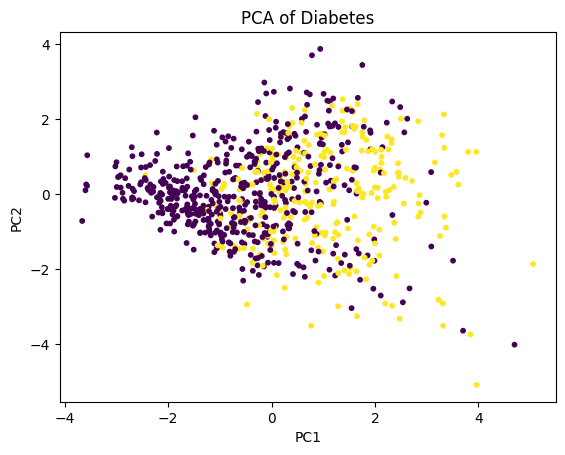

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(df.drop(columns="Outcome").fillna(df.median()))
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3))
plt.scatter(pcs[:, 0], pcs[:, 1], c=df["Outcome"], s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Diabetes")
plt.show()

---
## Question 2

### Q2.1 Read the data and preprocess

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/IRIS.csv")
X = StandardScaler().fit_transform(df.drop(columns="Species"))   # clustering never sees the answer column
print(X.shape)

(150, 4)


### Q2.2 Cluster with different distance metrics (Euclidean, Manhattan) and linkages (single, complete)
### Q2.4 Compare with Silhouette Score and Davies-Bouldin Index

*One code cell below answers both parts.*

In [8]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

rows = []
for metric in ["euclidean", "manhattan"]:
    for link in ["single", "complete"]:
        labels = AgglomerativeClustering(n_clusters=3, metric=metric, linkage=link).fit_predict(X)
        rows.append([metric, link, silhouette_score(X, labels), davies_bouldin_score(X, labels)])
results = pd.DataFrame(rows, columns=["Metric", "Linkage", "Silhouette (higher better)", "Davies-Bouldin (lower better)"])
results.round(4)

,Metric,Linkage,Silhouette (higher better),Davies-Bouldin (lower better)
0,euclidean,single,0.5046,0.4929
1,euclidean,complete,0.4496,0.7584
2,manhattan,single,0.4949,0.5344
3,manhattan,complete,0.4350,0.7877


### Q2.3 Plot the dendrogram

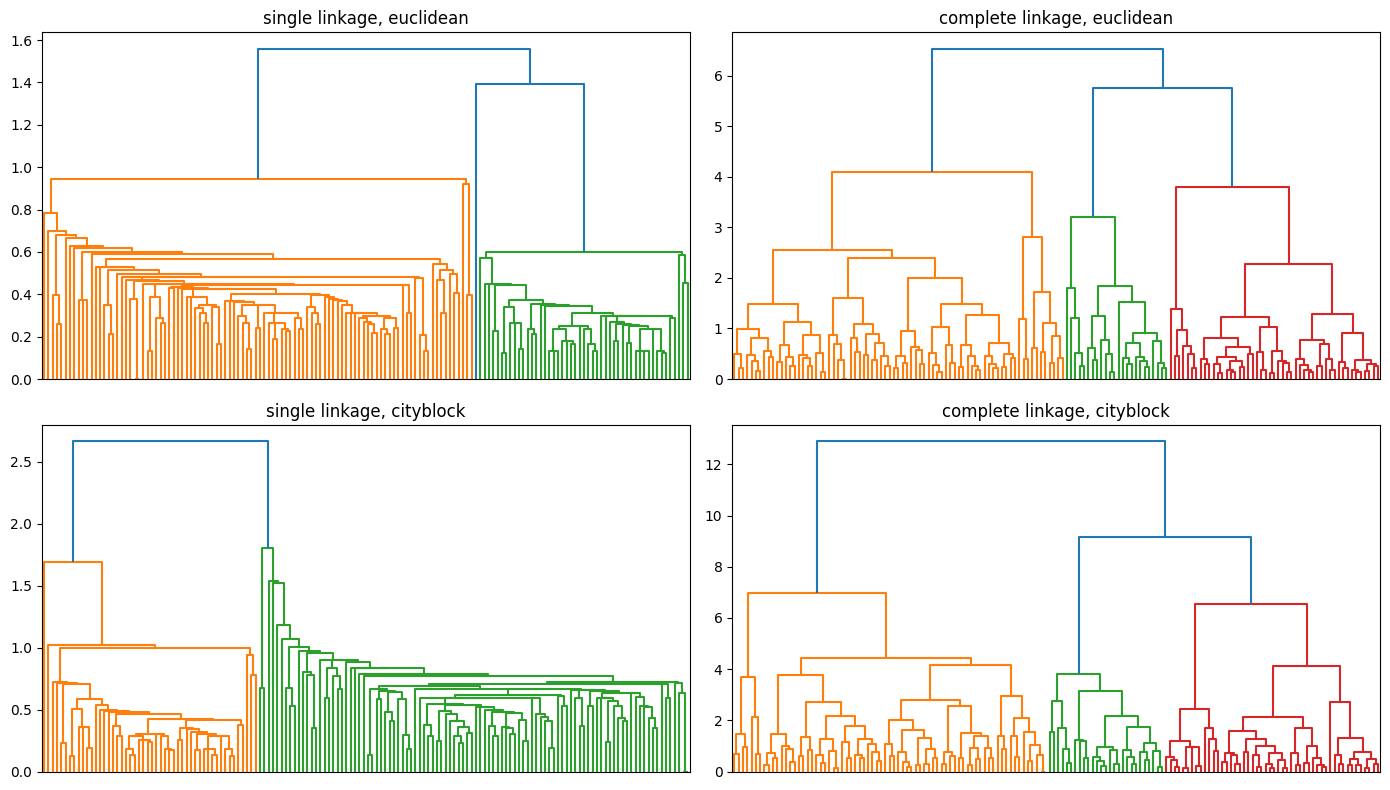

In [9]:
import scipy.cluster.hierarchy as sch

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (metric, link) in zip(axes.ravel(), [("euclidean", "single"), ("euclidean", "complete"),
                                              ("cityblock", "single"), ("cityblock", "complete")]):
    sch.dendrogram(sch.linkage(X, method=link, metric=metric), ax=ax, no_labels=True)
    ax.set_title(f"{link} linkage, {metric}")
plt.tight_layout()
plt.show()

In scipy, Manhattan distance is called **`cityblock`**. In sklearn it's `manhattan`. Same thing.